In [4]:
import pandas as pd

fake_df = pd.read_csv('Fake.csv')
true_df = pd.read_csv('True.csv')
fake_df
true_df

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"
...,...,...,...,...
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017"
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017"
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017"
21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017"


In [5]:
fake_df = fake_df.dropna()
true_df = true_df.dropna()
fake_df
true_df

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"
...,...,...,...,...
21412,'Fully committed' NATO backs new U.S. approach...,BRUSSELS (Reuters) - NATO allies on Tuesday we...,worldnews,"August 22, 2017"
21413,LexisNexis withdrew two products from Chinese ...,"LONDON (Reuters) - LexisNexis, a provider of l...",worldnews,"August 22, 2017"
21414,Minsk cultural hub becomes haven from authorities,MINSK (Reuters) - In the shadow of disused Sov...,worldnews,"August 22, 2017"
21415,Vatican upbeat on possibility of Pope Francis ...,MOSCOW (Reuters) - Vatican Secretary of State ...,worldnews,"August 22, 2017"


In [6]:
true_df.info()
fake_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21417 entries, 0 to 21416
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    21417 non-null  object
 1   text     21417 non-null  object
 2   subject  21417 non-null  object
 3   date     21417 non-null  object
dtypes: object(4)
memory usage: 669.4+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23481 entries, 0 to 23480
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    23481 non-null  object
 1   text     23481 non-null  object
 2   subject  23481 non-null  object
 3   date     23481 non-null  object
dtypes: object(4)
memory usage: 733.9+ KB


In [7]:
# Combine, label, shuffle, and split the data
from sklearn.model_selection import train_test_split

# Add label columns: 0 for fake, 1 for true
fake_df['label'] = 0
true_df['label'] = 1

data = pd.concat([fake_df, true_df], ignore_index=True)

# Shuffle the combined dataframe
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

# Split into features (X) and target (y)
X = data.drop('label', axis=1)
y = data['label']

# Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Show the shape of the splits
print('Training set shape:', X_train.shape)
print('Test set shape:', X_test.shape)

Training set shape: (35918, 4)
Test set shape: (8980, 4)


In [8]:
# Preprocessing: Tokenization and Padding for Deep Learning models
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000
max_len = 300

# Replace 'text' with the actual column name containing news text
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train['text'])

X_train_seq = tokenizer.texts_to_sequences(X_train['text'])
X_test_seq = tokenizer.texts_to_sequences(X_test['text'])

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

# CNN Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

cnn_model = Sequential([
    Embedding(max_words, 64, input_length=max_len),
    Conv1D(64, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dropout(0.5),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

cnn_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
cnn_model.fit(X_train_pad, y_train, epochs=3, batch_size=64, validation_split=0.1)

# LSTM Model
from tensorflow.keras.layers import LSTM

lstm_model = Sequential([
    Embedding(max_words, 64, input_length=max_len),
    LSTM(32),
    Dropout(0.5),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])

lstm_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
lstm_model.fit(X_train_pad, y_train, epochs=3, batch_size=64, validation_split=0.1)



Epoch 1/3


c:\Users\dell\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


506/506 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.8146 - loss: 0.3359 - val_accuracy: 0.9908 - val_loss: 0.0327
Epoch 2/3
506/506 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9918 - loss: 0.0279 - val_accuracy: 0.9958 - val_loss: 0.0140
Epoch 3/3
506/506 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - accuracy: 0.9981 - loss: 0.0083 - val_accuracy: 0.9969 - val_loss: 0.0108
Epoch 1/3
506/506 ━━━━━━━━━━━━━━━━━━━━ 32s 60ms/step - accuracy: 0.7374 - loss: 0.4943 - val_accuracy: 0.8001 - val_loss: 0.2817
Epoch 2/3
506/506 ━━━━━━━━━━━━━━━━━━━━ 32s 63ms/step - accuracy: 0.8205 - loss: 0.3017 - val_accuracy: 0.9847 - val_loss: 0.1007
Epoch 3/3
506/506 ━━━━━━━━━━━━━━━━━━━━ 29s 58ms/step - accuracy: 0.9806 - loss: 0.0964 - val_accuracy: 0.9674 - val_loss: 0.1235


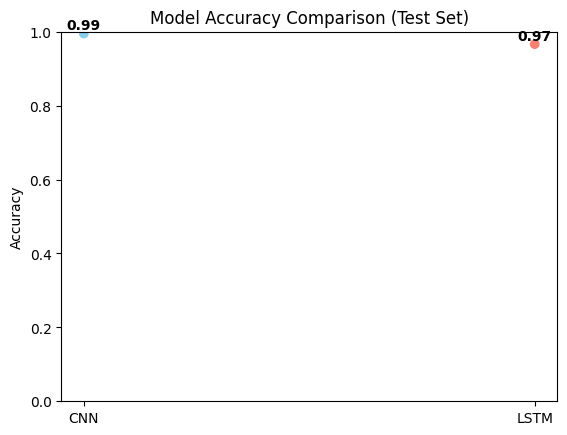

In [9]:
# Evaluate both models on the test set
cnn_loss, cnn_acc = cnn_model.evaluate(X_test_pad, y_test, verbose=0)
lstm_loss, lstm_acc = lstm_model.evaluate(X_test_pad, y_test, verbose=0)

# Plotting comparison graph
import matplotlib.pyplot as plt

models = ['CNN', 'LSTM']
accuracies = [cnn_acc, lstm_acc]

plt.scatter(models, accuracies, color=['skyblue', 'salmon'])
plt.ylim(0, 1)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison (Test Set)')
for i, v in enumerate(accuracies):
    plt.text(i, v + 0.01, f'{v:.2f}', ha='center', fontweight='bold')
plt.show()

In [10]:
from newspaper import Article

def predict_article_from_url(url, tokenizer, cnn_model, max_len=300):
    # Step 1: Download and parse the article
    try:
        article = Article(url)
        article.download()
        article.parse()
        text = article.text
    except Exception as e:
        print(f"Error extracting article: {e}")
        return None

    if not text.strip():
        print("Could not extract text from the provided URL.")
        return None

    # Step 2: Preprocess the text (tokenize and pad)
    seq = tokenizer.texts_to_sequences([text])
    pad = pad_sequences(seq, maxlen=max_len, padding='post')

    # Step 3: Predict using the CNN model
    pred = cnn_model.predict(pad)[0][0]
    label = "True" if pred > 0.5 else "Fake"
    print(f"Prediction: {label} news (probability: {pred:.2f})")
    return label, pred

# Example usage:
url = input("Enter a news article URL: ")
predict_article_from_url(url, tokenizer, cnn_model, max_len)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Prediction: True news (probability: 1.00)


('True', np.float32(0.99999994))

In [11]:
# Paste article text and predict using the trained CNN model
article_text = input('Paste the article text here: ')

if article_text.strip():
    seq = tokenizer.texts_to_sequences([article_text])
    pad = pad_sequences(seq, maxlen=300, padding='post')
    pred = cnn_model.predict(pad)[0][0]
    label = 'True' if pred > 0.5 else 'Fake'
    print(f'Prediction: {label} news (probability: {pred:.2f})')
else:
    print('No text provided.')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Prediction: Fake news (probability: 0.00)


In [13]:
cnn_model.save("cnn_model.h5")




In [14]:
import joblib
joblib.dump(tokenizer, "tokenizer.pkl")

print("✅ Model and tokenizer saved successfully.")

✅ Model and tokenizer saved successfully.
